# Customer Churn Prediction — End-to-End Analysis
**Capstone project · IBM Telco Customer Churn dataset**

This notebook tells the full story: business problem → data quality → EDA → features → modelling → imbalance → threshold → explainability → segmentation → business impact.
Heavy training is done once by `python run_pipeline.py`; this notebook loads those results and re-computes the light parts live so every number is reproducible.

**Contents:** 1 Problem · 2 Data & quality · 3 EDA · 4 Features · 5 v1 baseline vs improved · 6 Model comparison · 7 Imbalance · 8 Threshold & business value · 9 Final test results · 10 Explainability · 11 Segments · 12 Fairness · 13 Conclusions

## 1 · Business problem
A telecom operator loses revenue whenever a customer leaves, and acquiring a new customer costs far more than keeping one. **Goal:** rank customers by churn probability so a limited retention budget is spent on the right people, and quantify the value of doing so.

*Success is not accuracy.* With 26.5% churn, a model that never flags anyone is 73.5% accurate and worthless. We judge the model by **PR-AUC / ROC-AUC (ranking quality)**, **recall at the chosen threshold (churners caught)** and **net business benefit**.

In [1]:
import json, warnings, sys, os
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
os.chdir(os.path.abspath(".."))
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from src.utils import load_config
cfg = load_config()
df = pd.read_csv(cfg["data"]["raw_path"])
report = json.load(open(cfg["model"]["report_path"]))
fig = lambda name, w=900: display(Image("reports/figures/" + name, width=w))
print(df.shape); df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2 · Data & quality checks

In [2]:
print(df.dtypes.value_counts().to_string()); print()
print("Churn rate:", round((df.Churn=='Yes').mean(),4), "| duplicate IDs:", df.customerID.duplicated().sum())
blank = df[df.TotalCharges.astype(str).str.strip()==""]
print("Blank TotalCharges:", len(blank), "-> all have tenure == 0:", (blank.tenure==0).all())
dq = json.load(open("reports/data_quality_report.json"))
pd.DataFrame(dq["checks"])

str        18
int64       2
float64     1

Churn rate: 0.2654 | duplicate IDs: 0
Blank TotalCharges: 11 -> all have tenure == 0: True


,check,passed,detail
0,required columns,False,missing=['tenure']
1,null percentage,True,threshold=5.0%
2,hidden blank values,False,{'TotalCharges': 11}
3,target column,True,"distribution={'No': 0.7346, 'Yes': 0.2654}"
4,category values,True,all within expected sets
5,numeric ranges,True,ok
6,duplicates,True,rows=0 ids=0


**Finding.** `TotalCharges` is stored as text and 11 rows are blank. All 11 are brand-new customers (tenure = 0), so the correct value is **$0** — not the median that v1 used (that invented ~$1,400 of lifetime spend for customers who had not been billed yet).

## 3 · Exploratory data analysis

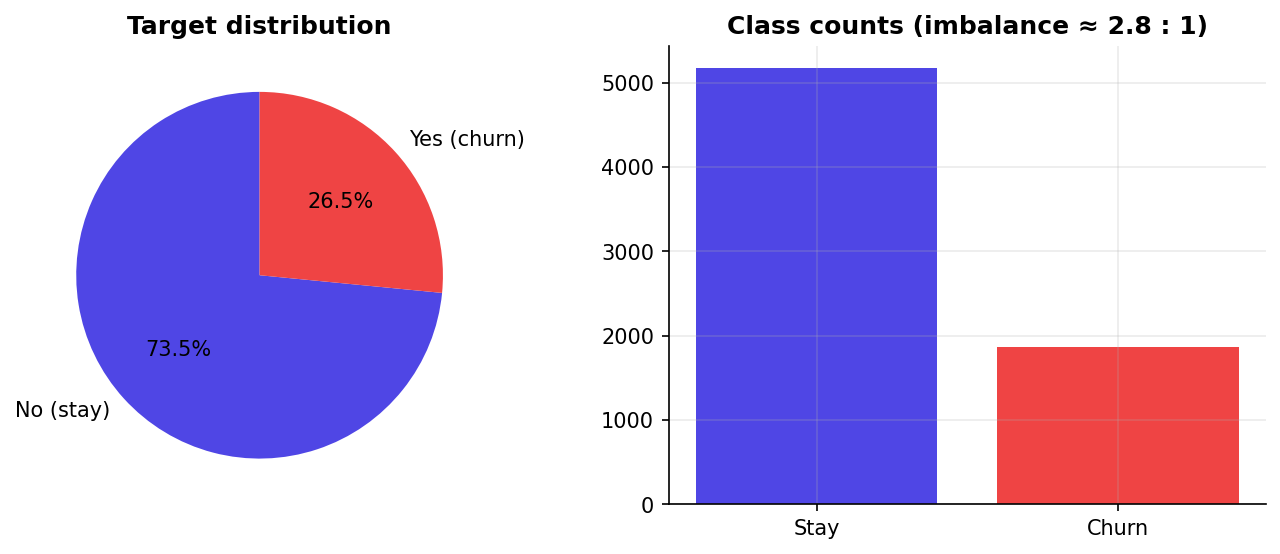

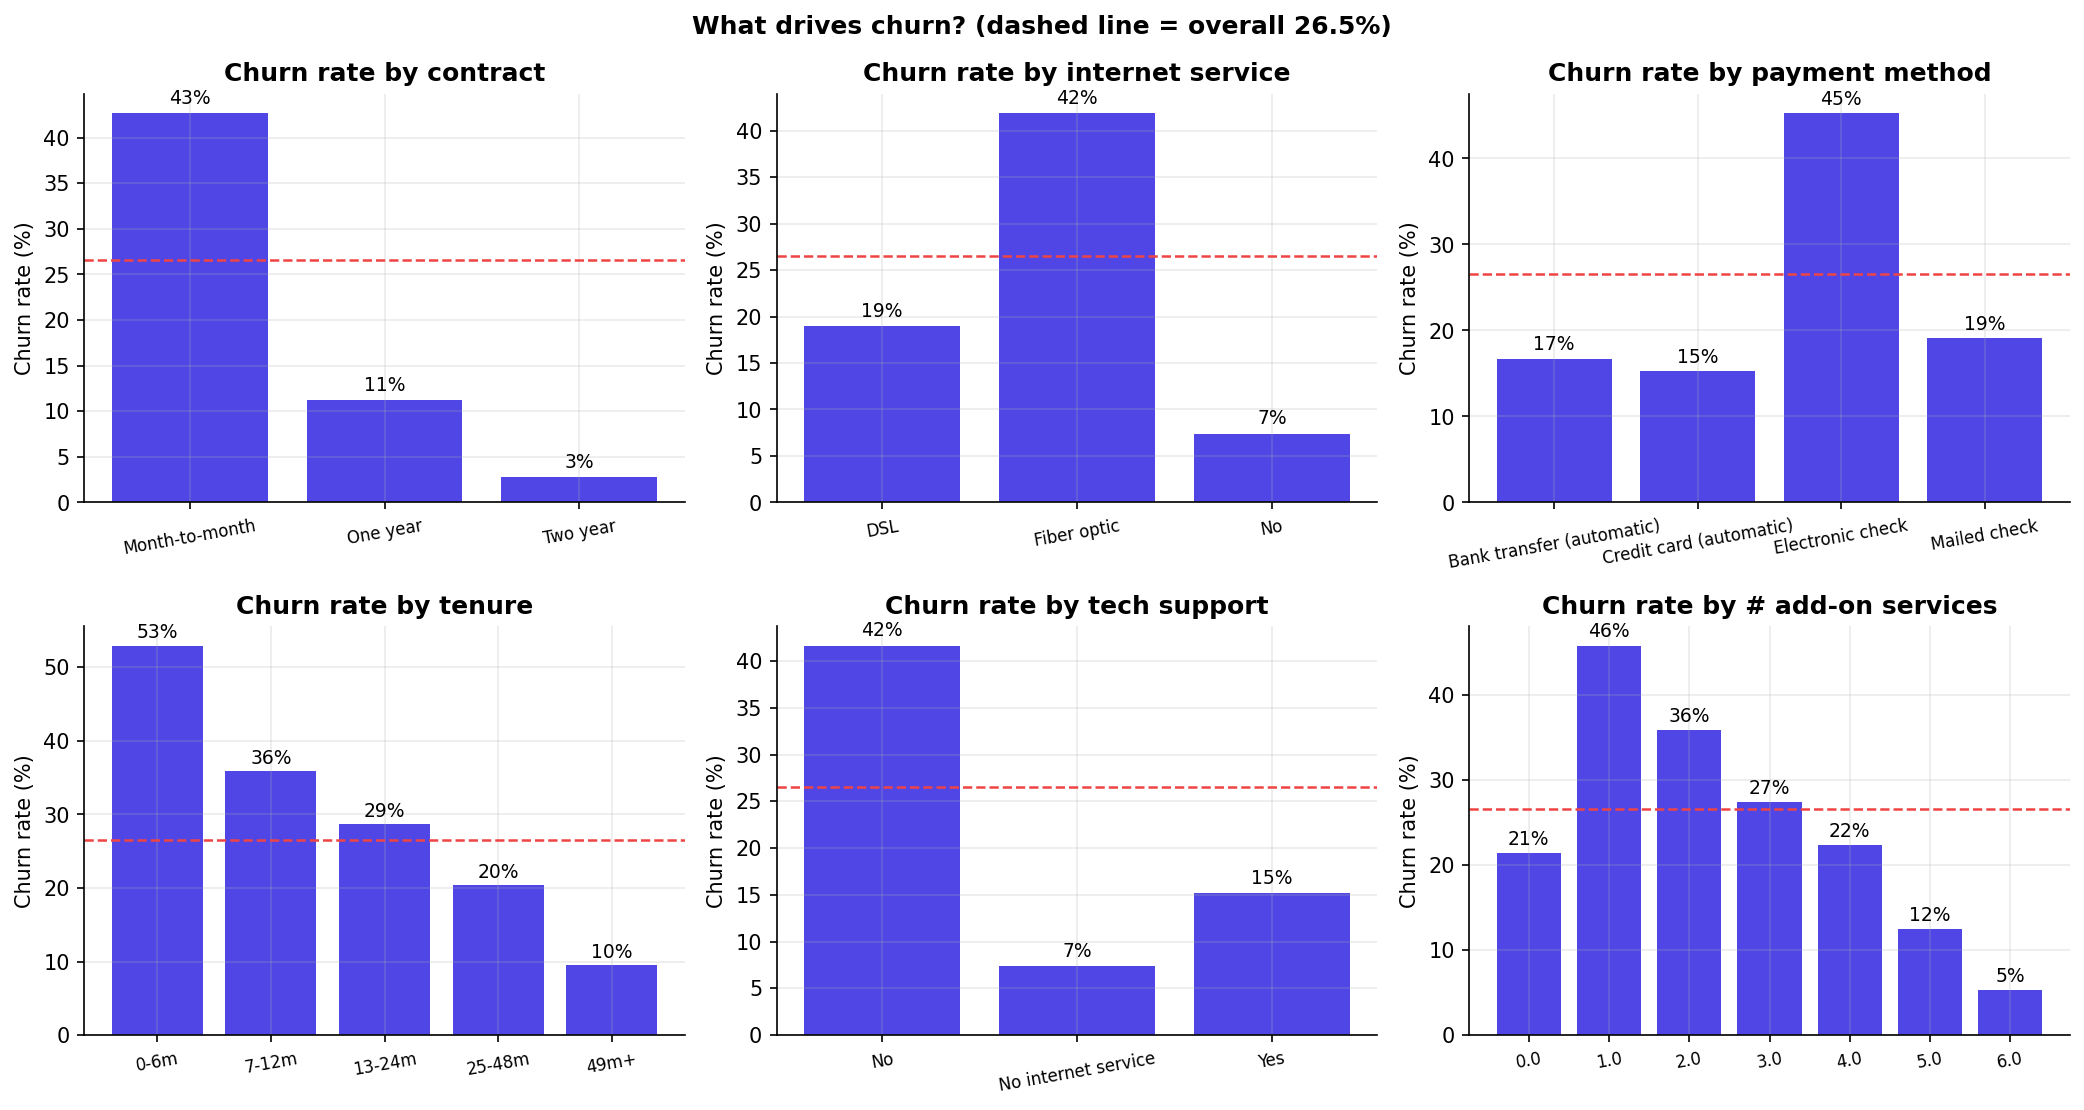

In [3]:
fig('eda_target.png', 700); fig('eda_churn_drivers.png', 1000)

In [4]:
ins = json.load(open("reports/eda_insights.json"))
print("Churn by contract:", {k: f'{v:.1%}' for k,v in ins['by_contract'].items()})
print("Churn by internet :", {k: f'{v:.1%}' for k,v in ins['by_internet'].items()})
print("Churn by payment  :", {k: f'{v:.1%}' for k,v in ins['by_payment'].items()})
print("Gender churn      :", {k: f'{v:.1%}' for k,v in ins['gender_churn'].items()}, "<- no real difference")

Churn by contract: {'Month-to-month': '42.7%', 'One year': '11.3%', 'Two year': '2.8%'}
Churn by internet : {'DSL': '19.0%', 'Fiber optic': '41.9%', 'No': '7.4%'}
Churn by payment  : {'Bank transfer (automatic)': '16.7%', 'Credit card (automatic)': '15.2%', 'Electronic check': '45.3%', 'Mailed check': '19.1%'}
Gender churn      : {'Female': '26.9%', 'Male': '26.2%'} <- no real difference


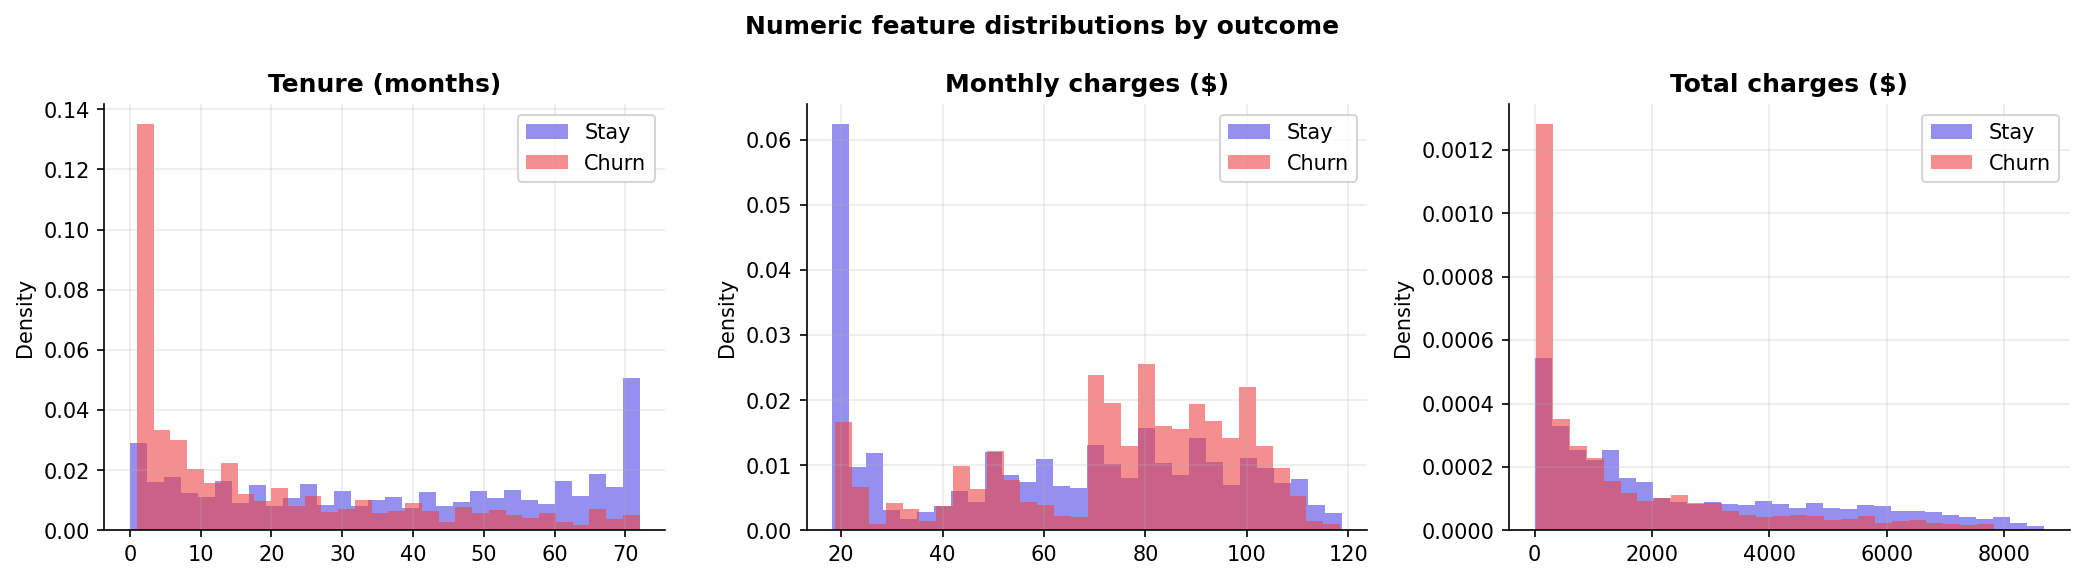

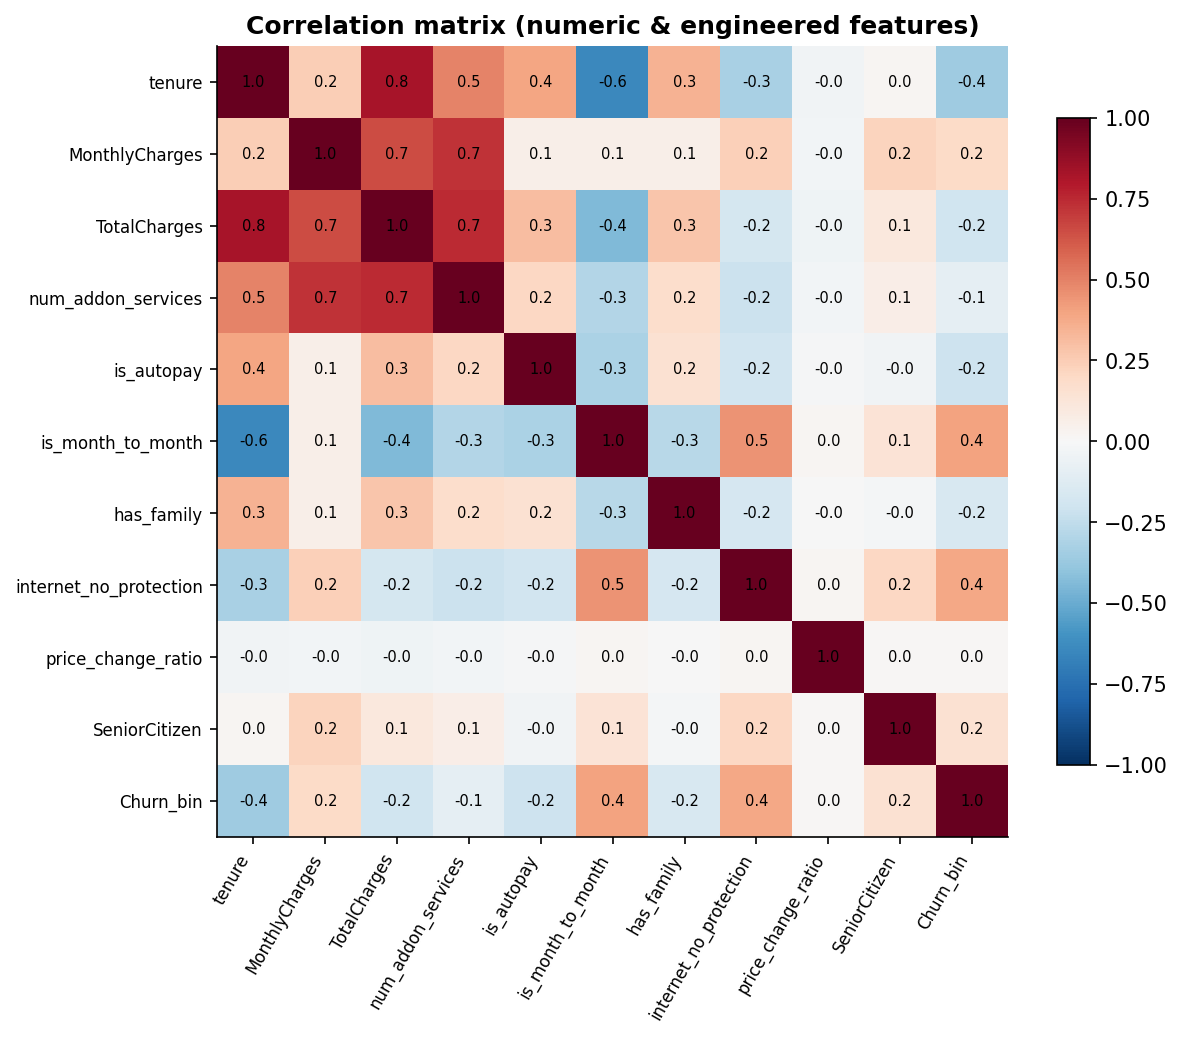

In [5]:
fig('eda_numeric.png', 1000); fig('eda_correlation.png', 650)

**Key EDA insights**
1. **Contract** is the strongest single signal: month-to-month customers churn ~43%, two-year ~3%.
2. **Tenure**: the first 6 months are the danger zone (≈53% churn); loyalty compounds.
3. **Fiber-optic** customers churn ~42% vs ~19% for DSL (price/quality expectations).
4. **Electronic-check** payers churn ~45% — auto-pay customers are far stickier.
5. **Support/security add-ons** protect: customers *without* tech support churn 42% vs 15% with it.
6. **Gender** shows no meaningful difference → excluded from the model (fairness + no signal).

## 4 · Feature engineering
Business-driven features live in `src/feature_engineering.py` inside the sklearn Pipeline (same code in training and in the live app).

In [6]:
from src.feature_engineering import ChurnFeatureEngineer
fe = ChurnFeatureEngineer(True, cfg["features"]["drop_columns"]).transform(df)
new = ["num_addon_services","num_protection_services","has_streaming","has_internet","internet_no_protection","is_autopay","is_month_to_month","has_family","avg_monthly_billed","price_change_ratio","tenure_bucket"]
fe[new].head()

,num_addon_services,num_protection_services,has_streaming,has_internet,internet_no_protection,is_autopay,is_month_to_month,has_family,avg_monthly_billed,price_change_ratio,tenure_bucket
0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,29.850000,1.000000,0-6m
1,2.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,55.573529,1.024768,25-48m
2,2.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0,54.075000,0.995839,0-6m
3,3.0,3.0,0.0,1.0,0.0,1.0,0.0,0.0,40.905556,1.034089,25-48m
4,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,75.825000,0.932410,0-6m


### Ablation: do the engineered features help?

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from src.feature_engineering import get_feature_lists
y = (df.Churn=="Yes").astype(int); X = df.drop(columns="Churn")
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for label, add, drop in [("raw features (+gender)", False, []), ("raw, gender dropped", False, ["gender"]), ("+ engineered, gender dropped (FINAL)", True, ["gender"])]:
    num, cat = get_feature_lists(add, drop)
    pre = ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    pipe = Pipeline([("fe", ChurnFeatureEngineer(add, drop)), ("pre", pre), ("clf", LogisticRegression(C=0.1, max_iter=3000))])
    r = cross_validate(pipe, Xtr, ytr, cv=cv, scoring=["roc_auc","average_precision"])
    rows.append({"feature set": label, "CV ROC-AUC": f"{r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.4f}", "CV PR-AUC": f"{r['test_average_precision'].mean():.4f} ± {r['test_average_precision'].std():.4f}"})
pd.DataFrame(rows)

,feature set,CV ROC-AUC,CV PR-AUC
0,raw features (+gender),0.8455 ± 0.0120,0.6607 ± 0.0190
1,"raw, gender dropped",0.8457 ± 0.0120,0.6606 ± 0.0189
2,"+ engineered, gender dropped (FINAL)",0.8474 ± 0.0113,0.6619 ± 0.0152


**Honest reading:** differences are far inside the fold-to-fold noise (±0.01). This dataset sits near a **performance ceiling of ≈0.85 ROC-AUC**; no feature trick moves it much. We keep the engineered features because they cost nothing and make explanations business-readable ("no tech support", "auto-pay"), and we drop `gender` because it adds nothing.

## 5 · Where v1 started vs. the improved pipeline

In [8]:
# Re-create the ORIGINAL v1 approach: label-encode everything, scale ALL columns on the FULL dataset (leakage), median-fill TotalCharges, HistGradientBoosting.
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score, roc_auc_score
d = df.drop(columns="customerID").copy()
d["TotalCharges"] = pd.to_numeric(d.TotalCharges, errors="coerce"); d["TotalCharges"] = d.TotalCharges.fillna(d.TotalCharges.median())
d["Churn"] = d.Churn.map({"Yes":1,"No":0})
for c in d.select_dtypes(exclude="number").columns: d[c] = LabelEncoder().fit_transform(d[c].astype(str))
feats = [c for c in d.columns if c != "Churn"]; d[feats] = StandardScaler().fit_transform(d[feats])        # <-- fitted BEFORE the split = leakage
a,b,c_,e = train_test_split(d[feats], d.Churn, test_size=.2, random_state=42, stratify=d.Churn)
m = HistGradientBoostingClassifier(learning_rate=.05, max_depth=3, max_iter=100, random_state=42).fit(a, c_)
p1 = m.predict_proba(b)[:,1]; pr1 = (p1>=.5).astype(int)
v1 = {"accuracy": accuracy_score(e,pr1), "precision": precision_score(e,pr1), "recall": recall_score(e,pr1), "F1": f1_score(e,pr1), "ROC-AUC": roc_auc_score(e,p1)}
t = report["test_metrics"]; dflt = report["test_metrics_default_threshold"]
cmp = pd.DataFrame({"v1-style (reproduced, fixed params)": v1,
  "v2 @ 0.50": {"accuracy": dflt["accuracy"], "precision": dflt["precision"], "recall": dflt["recall"], "F1": dflt["f1_score"], "ROC-AUC": dflt["roc_auc"]},
  f"v2 @ {report['threshold']} (cost-optimal)": {"accuracy": t["accuracy"], "precision": t["precision"], "recall": t["recall"], "F1": t["f1_score"], "ROC-AUC": t["roc_auc"]}}).round(3)
cmp

,"v1-style (reproduced, fixed params)",v2 @ 0.50,v2 @ 0.24 (cost-optimal)
accuracy,0.800,0.803,0.735
precision,0.664,0.666,0.500
recall,0.497,0.521,0.821
F1,0.569,0.585,0.622
ROC-AUC,0.845,0.844,0.844


**What this table shows**
* **Ranking quality (ROC-AUC) is essentially unchanged (~0.845)** — the data has a ceiling; claiming otherwise would be dishonest. (The README of v1 advertised 83% accuracy / F1 0.81; the code actually produced 80.5% / 0.58.)
* **At the default 0.50 threshold** v1 and v2 behave the same: the model misses about half of the churners.
* **The real gain** comes from decision-making: moving to the cost-optimal threshold lifts **recall from ~52% to ~82%**, at the price of lower precision and accuracy. We chose that deliberately — see section 8.

## 6 · Model comparison (5-fold stratified CV on the training set only)

,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,n_combinations
LogisticRegression,0.662737,0.014881,0.847511,0.011069,6
RandomForest,0.66287,0.024623,0.847043,0.009525,9
HistGradientBoosting,0.664577,0.020461,0.848328,0.010715,24
XGBoost,0.666719,0.020389,0.849071,0.010539,16


one-standard-error rule: best was XGBoost (0.6667); floor = best - 1 SE = 0.6576; candidates within the floor = ['LogisticRegression', 'RandomForest', 'HistGradientBoosting', 'XGBoost']; simplest of them = LogisticRegression


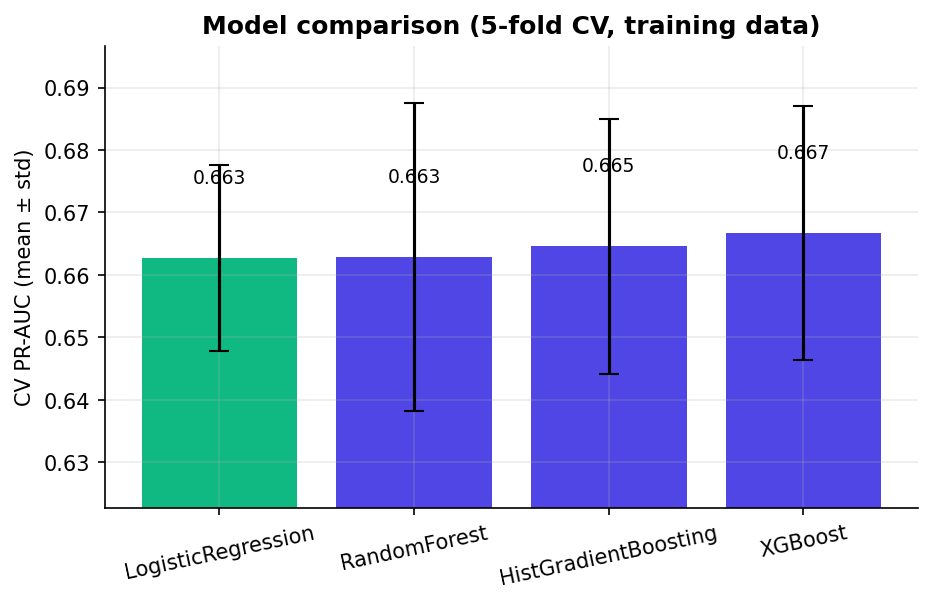

In [9]:
comp = pd.DataFrame(report["model_comparison"]).T[["pr_auc_mean","pr_auc_std","roc_auc_mean","roc_auc_std","n_combinations"]].round(4)
display(comp); print(report["selection_reason"]); fig("model_comparison.png", 600)

**Selection rule.** All four models are statistically tied (differences < 1 standard error). Following the *one-standard-error rule* we choose the **simplest** model in the tie: Logistic Regression — interpretable, fast, naturally well-calibrated, tiny to deploy. (Set `selection_rule: best` in `config.yaml` to pick the top mean instead.)

## 7 · Class imbalance: none vs class-weight vs SMOTE

,model,strategy,roc_auc,average_precision,recall,precision,f1
0,LogisticRegression,none,0.8475,0.6627,0.5324,0.6666,0.5914
1,LogisticRegression,class_weight,0.8474,0.6614,0.7926,0.5233,0.6303
2,LogisticRegression,SMOTE,0.8466,0.6598,0.7759,0.5290,0.6289


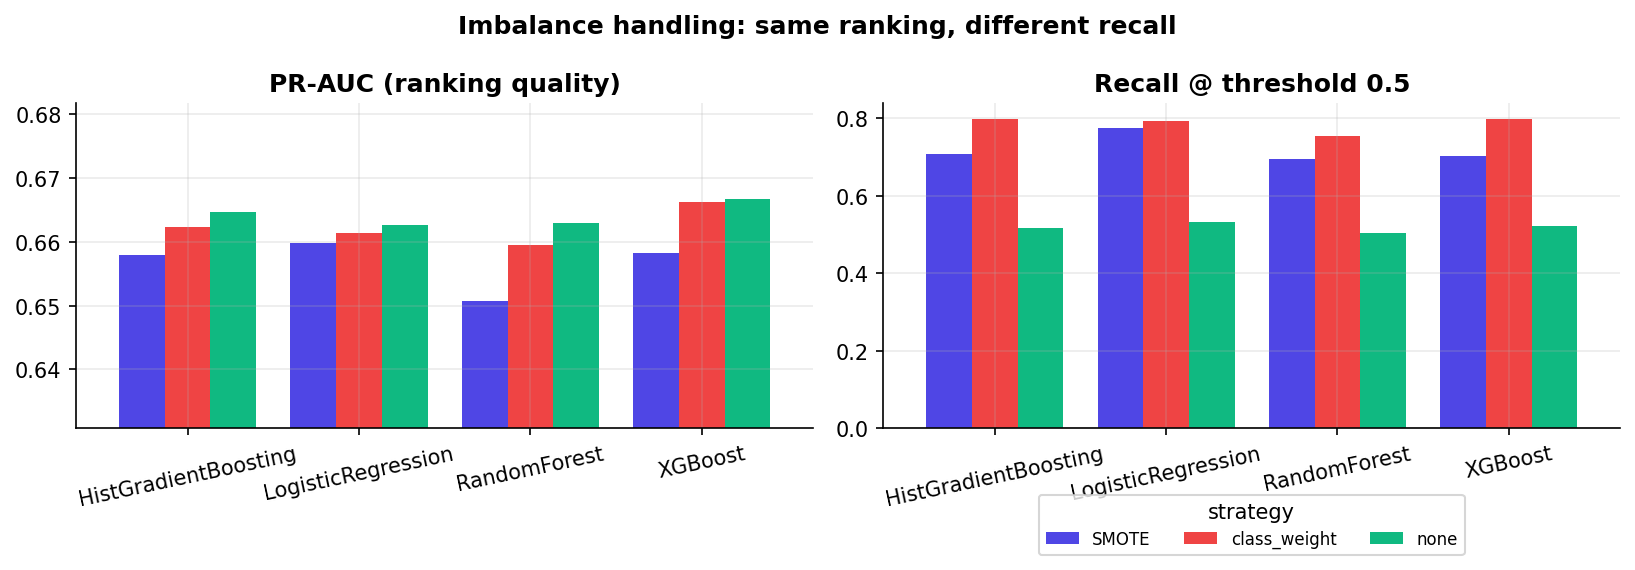

In [10]:
ab = pd.DataFrame(report['imbalance_ablation']); display(ab[ab.model=='LogisticRegression']); fig('imbalance_ablation.png', 1000)

**Insight.** Class weights and SMOTE raise recall at 0.5 (≈0.53 → ≈0.79) but **PR-AUC does not improve** — they simply shift the decision boundary, the same as lowering the threshold, while distorting the probabilities. We therefore train on the natural distribution (keeping probabilities honest) and move the **threshold** using business costs.

## 8 · Threshold selection from business economics

Assumptions: offer $50, success 30%, keeps 12 months of revenue
Theoretical threshold  = offer / (success x value) = 0.214
Empirical cost-optimal = 0.24   | F1-optimal = 0.32 | F2-optimal = 0.14


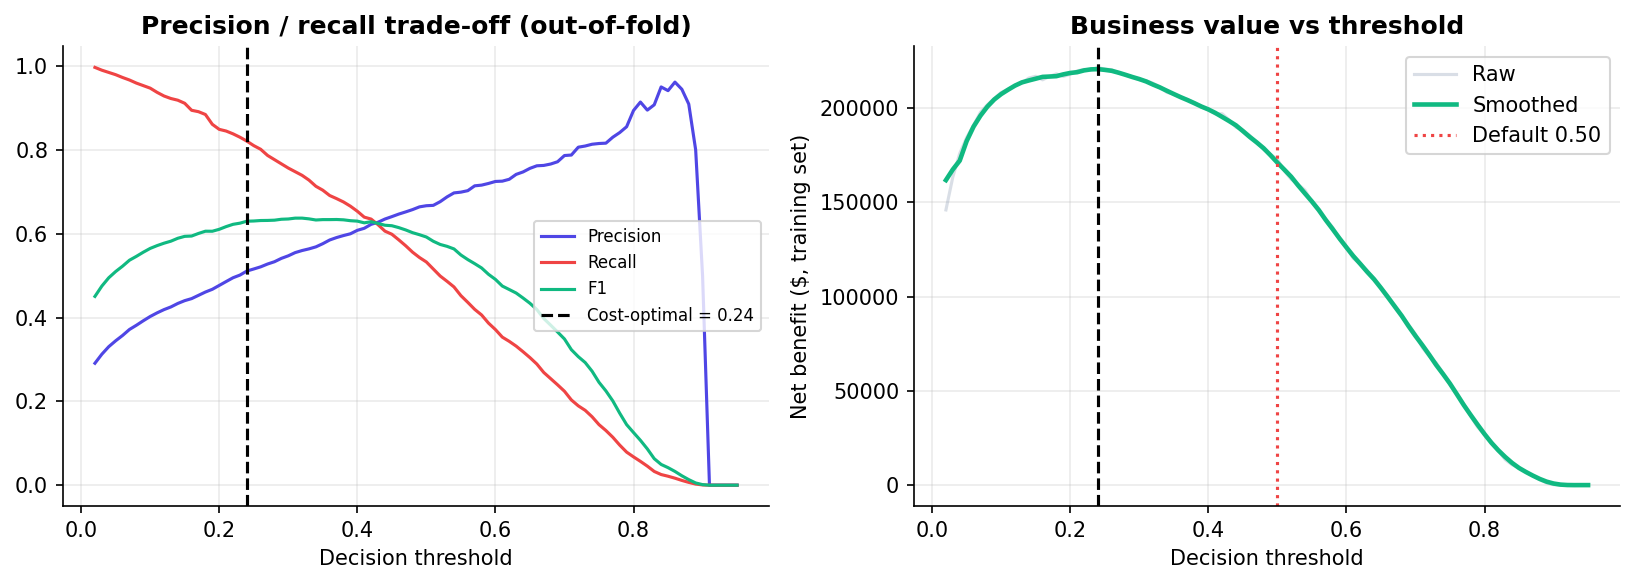

In [11]:
b = report["business_assumptions"]; th = report["threshold_analysis"]
print(f"Assumptions: offer ${b['retention_offer_cost']:.0f}, success {b['offer_success_rate']:.0%}, keeps {b['value_horizon_months']} months of revenue")
print(f"Theoretical threshold  = offer / (success x value) = {th['theoretical_threshold']}")
print(f"Empirical cost-optimal = {th['cost_optimal_threshold']}   | F1-optimal = {th['f1_optimal_threshold']} | F2-optimal = {th['f2_optimal_threshold']}")
fig("threshold_analysis.png", 1000)

In [12]:
sens = pd.DataFrame(th["sensitivity"]).pivot(index="offer_cost", columns="success_rate", values="best_threshold").round(2)
display(Markdown("**Sensitivity: best threshold as assumptions change** (rows = offer cost $, columns = offer success rate)")); display(sens)

**Sensitivity: best threshold as assumptions change** (rows = offer cost $, columns = offer success rate)

success_rate,0.1,0.2,0.3,0.5
offer_cost,,,,
10,0.13,0.07,0.05,0.02
25,0.30,0.16,0.09,0.07
50,0.55,0.30,0.24,0.13
100,0.86,0.55,0.42,0.26


In 13 of the 16 scenarios the optimum is **at or below 0.5**, so the default threshold is rarely right whenever a missed churner is worth more than a wasted offer. The 3 exceptions are the *expensive offer / low success rate* corners (e.g. $100 offer with 10% success -> optimum 0.86): when offers rarely work and cost a lot, we should contact fewer people. **The threshold is a business decision, not a statistical constant — re-run `python run_pipeline.py` after changing `config.yaml`.**

## 9 · Final evaluation on the untouched test set

Final model: LogisticRegression | threshold 0.24


,threshold,accuracy,balanced_accuracy,precision,recall,f1_score,mcc,roc_auc,pr_auc,brier,ece
test @0.50,0.50,0.8034,0.7134,0.6655,0.5214,0.5847,0.4643,0.8445,0.6498,0.1366,0.0252
test @ optimal,0.24,0.7346,0.7621,0.5000,0.8209,0.6215,0.4668,0.8445,0.6498,0.1366,0.0252


95% bootstrap CIs @ optimal threshold: {'roc_auc': [0.8216, 0.8653], 'pr_auc': [0.5964, 0.7004], 'recall': [0.7798, 0.8579], 'precision': [0.4603, 0.5388], 'f1_score': [0.5847, 0.6554]}
Confusion matrix @ optimal: {'true_negative': 728, 'false_positive': 307, 'false_negative': 67, 'true_positive': 307}


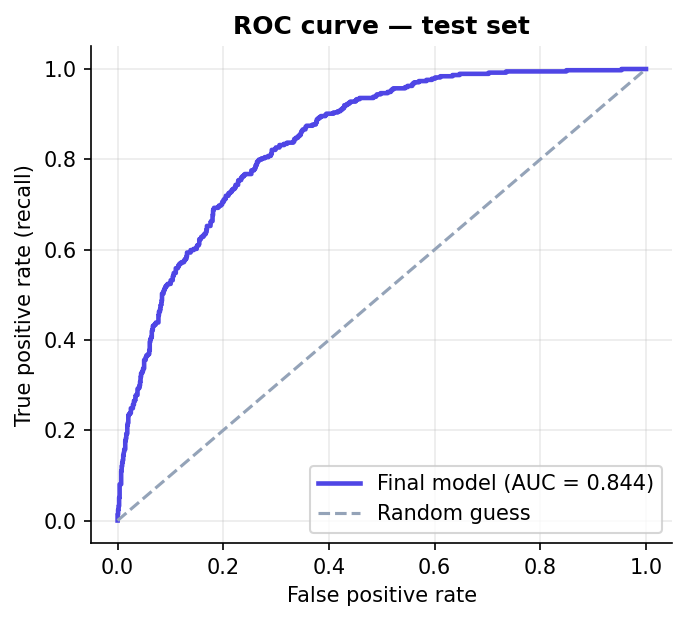

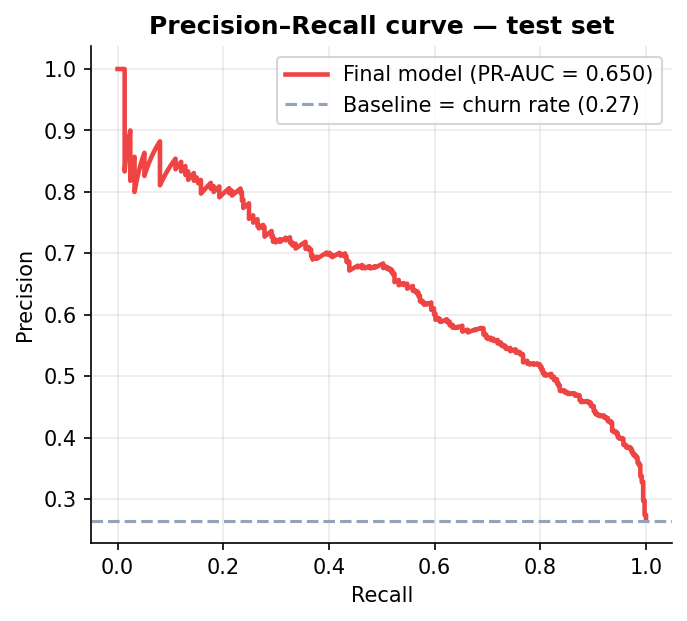

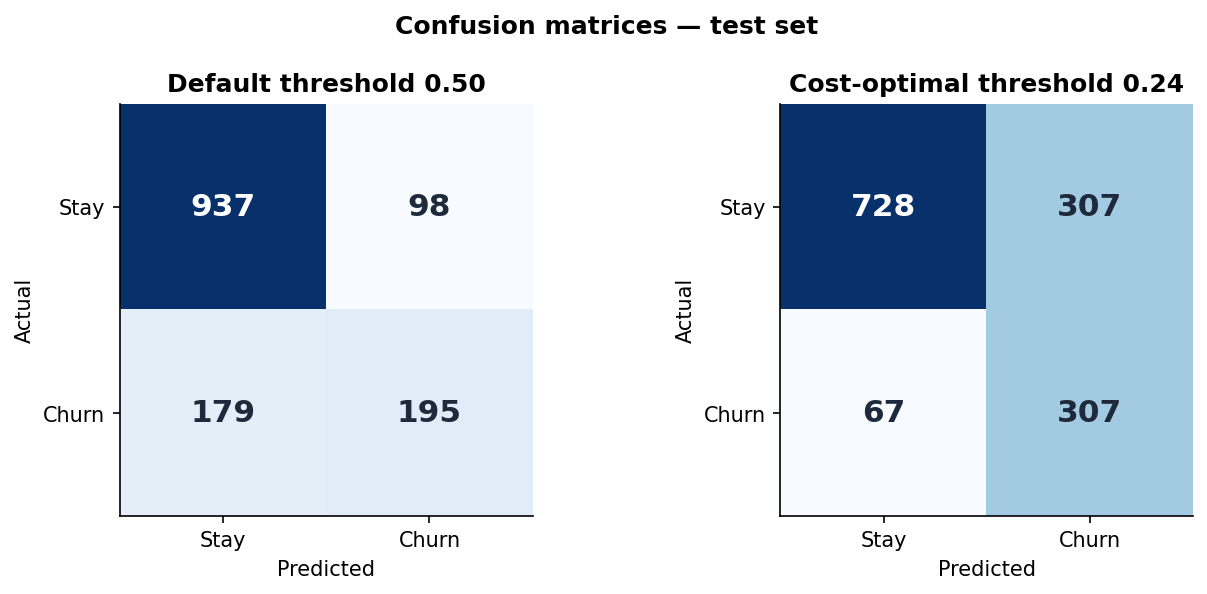

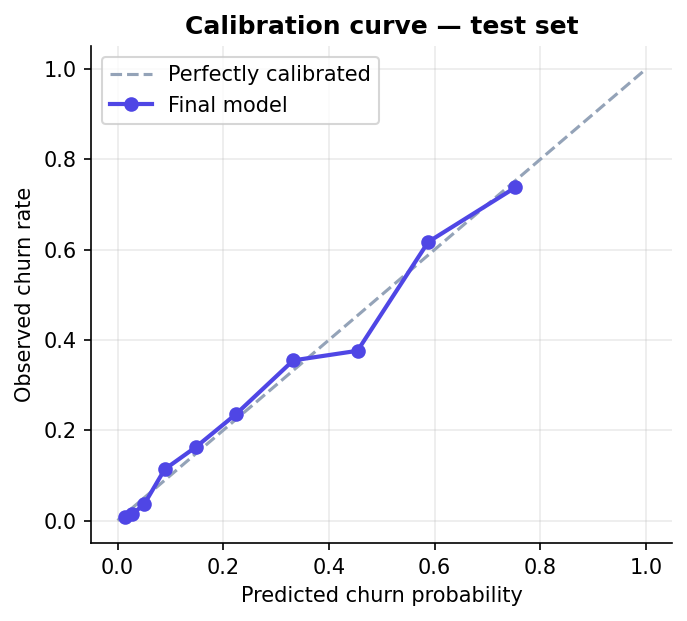

In [13]:
ci = report["bootstrap_95ci_at_optimal_threshold"]
print("Final model:", report["model_name"], "| threshold", report["threshold"])
display(pd.DataFrame({"test @0.50": report["test_metrics_default_threshold"], "test @ optimal": report["test_metrics"]}).T)
print("95% bootstrap CIs @ optimal threshold:", ci)
print("Confusion matrix @ optimal:", report["confusion_matrix"])
fig("roc_curve.png", 450); fig("pr_curve.png", 450); fig("confusion_matrices.png", 800); fig("calibration_curve.png", 450)

**Calibration** — predicted probabilities match observed churn rates (low ECE), so a score of 60% really means ≈60% of such customers churn. That is what lets us show the probability to a business user and use cost-based thresholds.

,decile,customers,churners,avg_prob,churn_rate,lift,cum_churners_captured
0,1,141,104,0.753,0.738,2.779,0.278
1,2,141,87,0.588,0.617,2.325,0.511
2,3,141,53,0.454,0.376,1.416,0.652
3,4,141,50,0.332,0.355,1.336,0.786
4,5,141,33,0.224,0.234,0.882,0.874
5,6,140,23,0.148,0.164,0.619,0.936
6,7,141,16,0.089,0.114,0.428,0.979
7,8,141,5,0.050,0.036,0.134,0.992
8,9,141,2,0.028,0.014,0.053,0.997
9,10,141,1,0.013,0.007,0.027,1.000


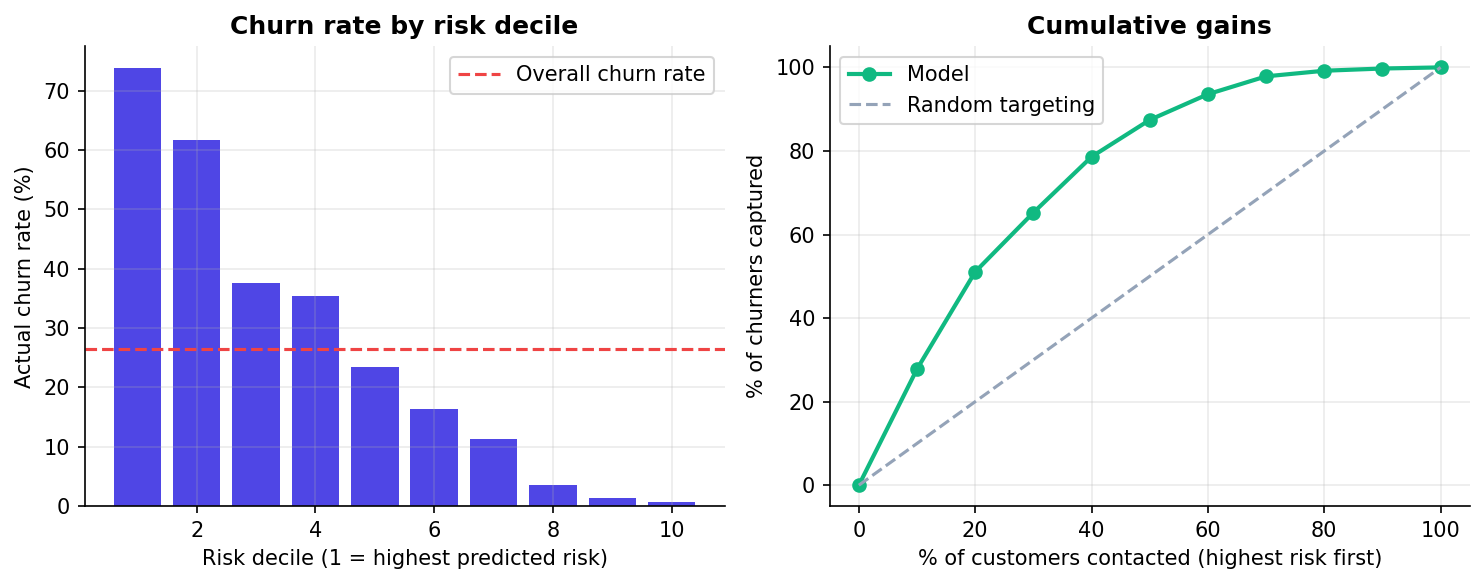

In [14]:
lt = pd.DataFrame(report["lift_table"]); display(lt.round(3)); fig("lift_gains.png", 1000)

**Business reading of the gains chart:** contacting the top 20% highest-risk customers reaches about half of all churners (2.5x better than random); the top 40% reaches ~79%.

,net benefit ($)
Contact nobody,0.00
Contact everyone,27523.64
Model @ default 0.50,40322.18
Model @ cost-optimal 0.24,51803.36


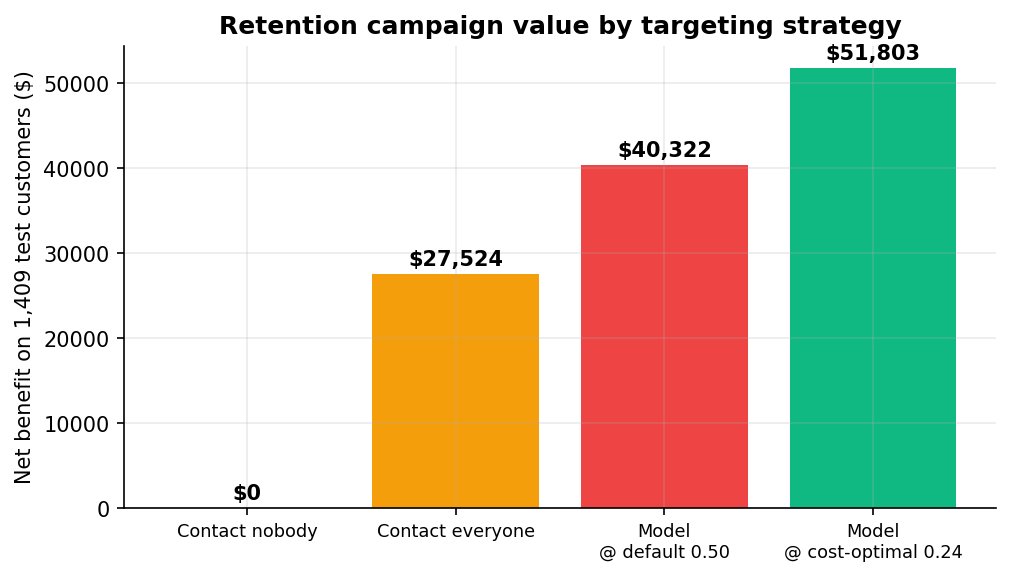

In [15]:
bz = pd.Series(report["business_test_net_benefit"]).rename("net benefit ($)"); display(bz.to_frame()); fig("business_value.png", 650)

## 10 · Explainability

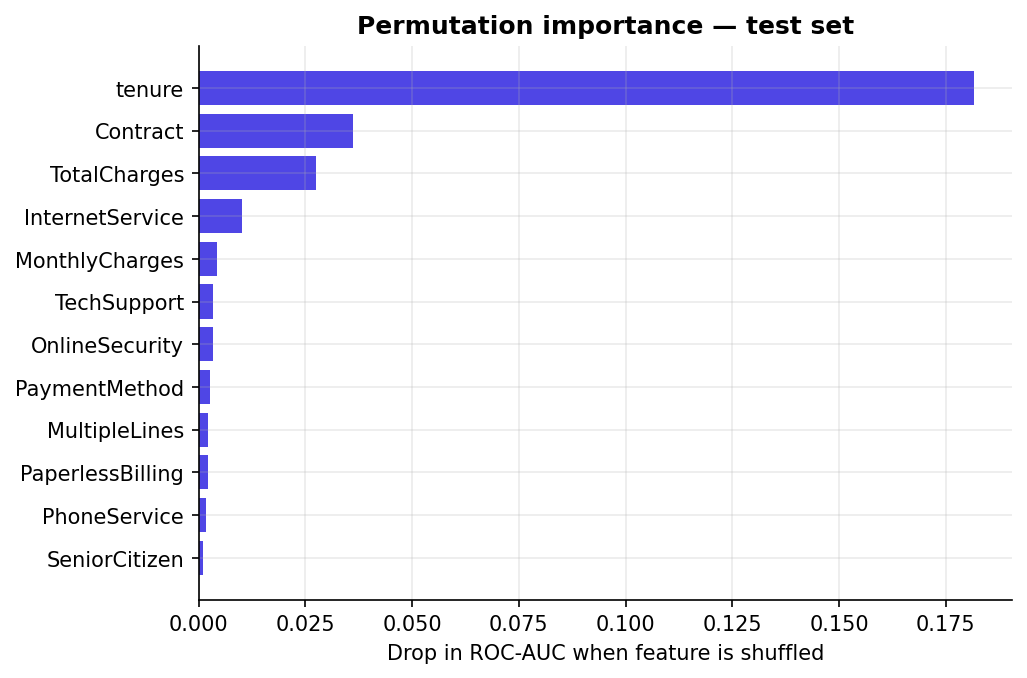

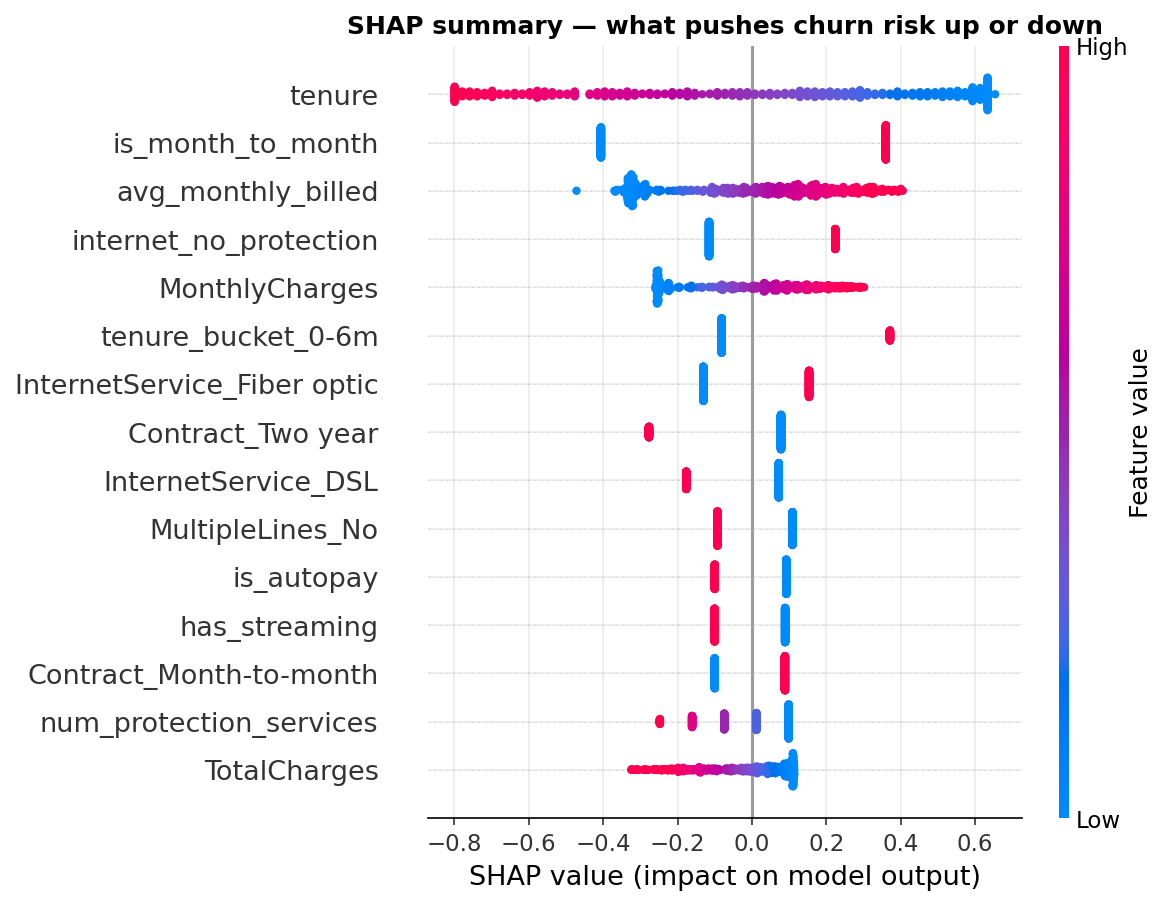

In [16]:
fig('permutation_importance.png', 650); fig('shap_summary.png', 800)

**Both methods agree:** tenure, contract type and internet service dominate. Short tenure (especially the first 6 months), month-to-month contracts, fiber optic and missing protection/tech-support add-ons push risk **up**; long tenure, 1–2 year contracts, protection add-ons and auto-pay pull it **down**. Monthly charges overlap strongly with tenure and the services a customer has (collinearity), so its individual SHAP effect should be read with caution. In the web app, every individual prediction also shows its own top risk-raising and protective factors plus suggested actions.

## 11 · Customer segmentation (K-means)

Chosen k = 4 | silhouette by k: {'3': 0.394, '4': 0.401, '5': 0.358}


,segment,customers,churn_rate,avg_tenure,avg_monthly,avg_addons,pct_month_to_month
0,S1,2373,0.474,15.053,77.579,1.832,0.874
1,S2,1521,0.242,10.160,29.580,0.298,0.725
2,S3,2158,0.154,56.890,90.594,4.160,0.245
3,S4,991,0.044,54.539,31.812,0.581,0.173


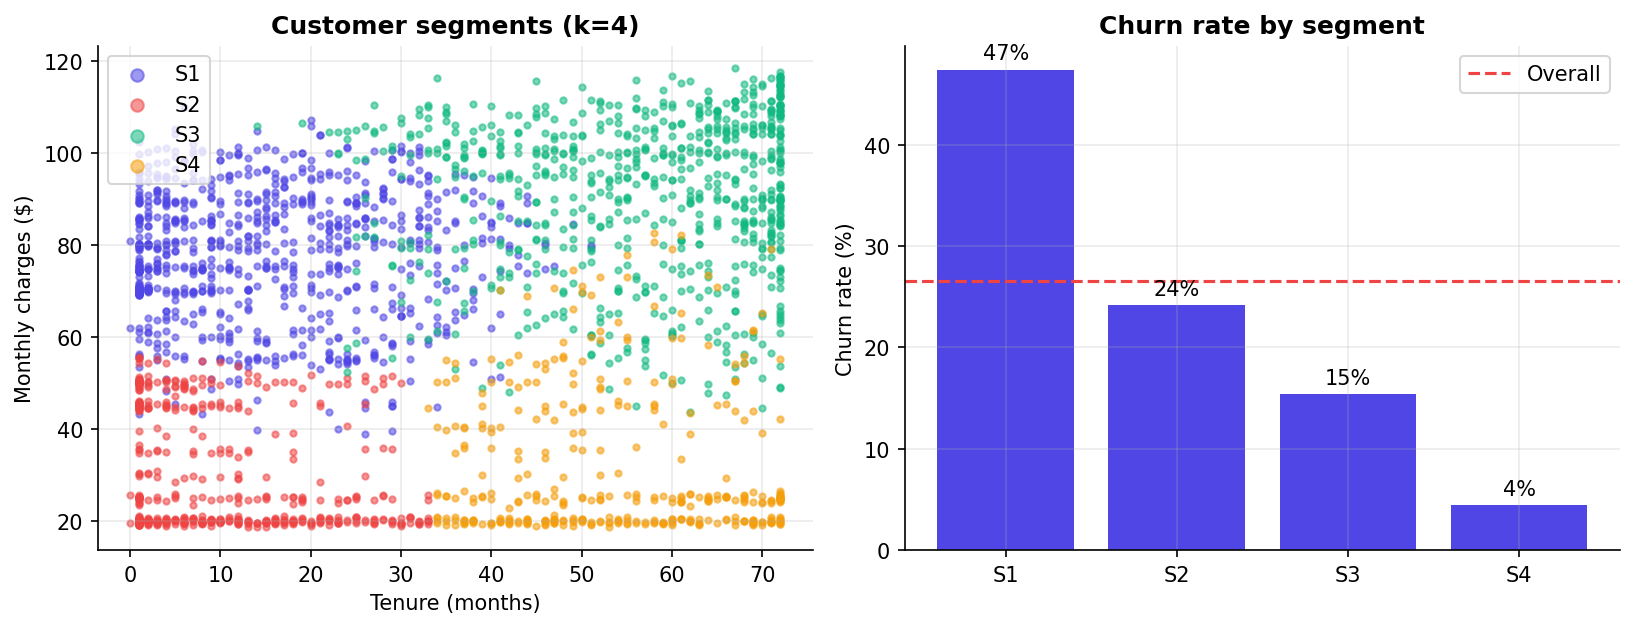

In [17]:
bi = json.load(open("reports/business_impact.json"))["segments"]
print("Chosen k =", bi["k"], "| silhouette by k:", {k: round(v,3) for k,v in bi["silhouette_by_k"].items()})
display(pd.DataFrame(bi["profile"])); fig("customer_segments.png", 1000)

| Segment | Profile | Churn | Suggested strategy |
|---|---|---|---|
| **S1 — At-risk mainstream** | ~15 months tenure, ~$78/month, mostly month-to-month | highest (~47%) | contract-upgrade offers, bill review |
| **S2 — Budget newcomers** | new, ~$30/month, almost no add-ons, month-to-month | ~24% | onboarding, light cross-sell |
| **S3 — Loyal premium** | ~57 months, ~$91/month, 4+ add-ons | ~15% | protect & reward (high revenue) |
| **S4 — Loyal low-cost** | ~55 months, ~$32/month, long contracts | lowest (~4%) | leave alone |

## 12 · Fairness audit

In [18]:
pd.DataFrame(report['fairness_audit'])

,attribute,group,n,actual_churn_rate,flag_rate,recall,precision,roc_auc
0,gender,Female,687,0.281,0.440,0.819,0.523,0.841
1,gender,Male,722,0.251,0.432,0.823,0.478,0.849
2,SeniorCitizen,0,1187,0.233,0.386,0.783,0.472,0.847
3,SeniorCitizen,1,222,0.441,0.703,0.929,0.583,0.776
4,Partner,No,736,0.337,0.550,0.859,0.526,0.821
5,Partner,Yes,673,0.187,0.311,0.746,0.450,0.854
6,Dependents,No,978,0.310,0.522,0.855,0.507,0.830
7,Dependents,Yes,431,0.165,0.239,0.676,0.466,0.854


**Reading:** gender is treated equally (not used by the model). Senior citizens are flagged far more often and the ranking quality is lower for them — their actual churn rate is also much higher (≈44%), but offers should not be allocated by age without human review. This is documented in `MODEL_CARD.md`.

## 13 · Conclusions
1. Built a **leak-free, reproducible pipeline** with automated data validation, tests and CI; fixed three v1 issues (scaler leakage, median-imputed TotalCharges, unsupported README claims).
2. Four tuned models are statistically tied at **ROC-AUC ≈ 0.85**; the simplest (Logistic Regression) is selected and is already well calibrated.
3. Imbalance techniques change recall only through the threshold; a **cost-based threshold** catches **~82% of churners** (vs ~52%) and is worth ~28% more retained value than the 0.5 default under the stated assumptions.
4. Churn is driven by **short tenure, month-to-month contracts, fiber optic, electronic-check payment and missing support/security add-ons**, giving concrete retention levers.
5. Delivered as a Flask web app + JSON API + batch scoring + Docker.

**Limitations & future work:** single public snapshot dataset; illustrative business numbers; association ≠ causation (run A/B retention tests); survival/time-to-churn modelling; monitoring for drift; uplift modelling to target customers *persuadable* by an offer.